# Activity 2: Integrate Deterministic AI Agents
**Blockchain Wonders workshop · about 30 minutes**

A community fund receives micro-grant applications. AI agents recommend **APPROVE** or **REJECT**.
We want every recommendation to be:

- **reproducible**: same input and same model give the same output, every time
- **explainable**: we can show *why*
- **attributable**: we know *which agent* and *which model version* made it

Explainable AI answers **why**. The blockchain answers **what happened, who acted, with which model and rules, when, and whether the record has changed since.**

All data is synthetic.

In [16]:
# Setup: run this cell first.
import os, sys
import numpy, pandas, matplotlib          # loads the packages in JupyterLite
try:
    import sklearn
except ImportError:
    print("scikit-learn not found: agents will use the built-in rule tree instead.")

if not os.path.isdir("wonders"):
    if os.path.isdir("../wonders"):
        sys.path.insert(0, "..")
    else:
        try:                                # Google Colab: upload the workshop zip
            from google.colab import files
            import zipfile
            print("Upload blockchain_wonders.zip")
            name = next(iter(files.upload()))
            zipfile.ZipFile(name).extractall(".")
            sys.path.insert(0, "blockchain_wonders")
        except ImportError:
            print("Cannot find the 'wonders' folder. Keep this notebook next to it.")

import wonders
print("Ready. wonders version", wonders.__version__)

Ready. wonders version 1.0


## 1. The data

In [17]:
import pandas as pd
from wonders import make_applications, FEATURE_RANGES

history = pd.DataFrame(make_applications())
print(len(history), "past applications;", f"{history.approved.mean():.0%} approved")
history.head()

400 past applications; 36% approved


,project_score,endorsements,prior_grants,household_income,family_size,amount_requested,approved
0,61,2,1,181,1,50,0
1,94,0,1,69,1,50,1
2,75,6,0,76,2,300,1
3,48,10,2,164,1,300,0
4,26,3,0,157,3,150,0


## 2. Train an agent and ask for a decision

The agent is a decision tree trained with a **fixed random seed**.

Agent(agent-A, decision-tree, model 7f5055ea01...)
{'application_id': 'APP-001', 'project_score': 82, 'endorsements': 7, 'prior_grants': 0, 'household_income': 45, 'family_size': 6, 'amount_requested': 100}
Application APP-001: APPROVE (confidence 91%) by agent-A
  model 7f5055ea0187...  rules grant-policy-v1
  Started from a baseline approval chance of 36%
    asked: project_score = 82 > 54.5
    asked: prior_grants = 0 <= 1.5
    asked: endorsements = 7 > 2.5
    asked: household_income = 45 <= 172.5
    project_score     raised the chance by 21%
    endorsements      raised the chance by 16%
    household_income  raised the chance by 10%
    prior_grants      raised the chance by 9%
  Final approval chance: 91%


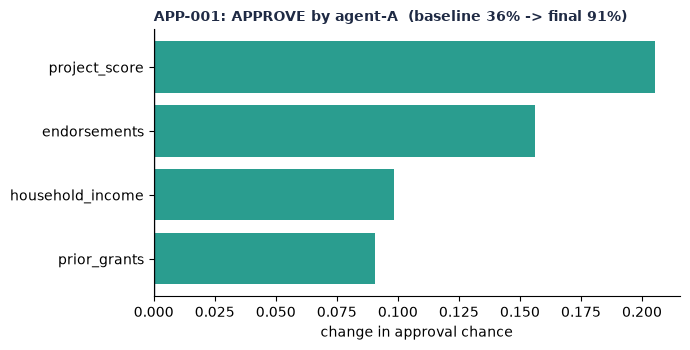

In [18]:
from wonders import Wallet, DeterministicAgent, sample_application, explain
from wonders.viz import draw_explanation

agent_a = DeterministicAgent(Wallet("agent-A", role="agent"), seed=11)
print(agent_a)

application = sample_application("APP-001")
print(application)

decision = agent_a.decide(application)
explain(decision)
draw_explanation(decision)

Read the explanation: the agent started from the overall approval rate, asked a few questions, and each answer moved the chance up or down.

**Your turn.** Change the application and see how the decision and explanation change. Try `prior_grants=3`, or `endorsements=1`.

Application APP-002: APPROVE (confidence 91%) by agent-A
  model 7f5055ea0187...  rules grant-policy-v1
  Started from a baseline approval chance of 36%
    asked: project_score = 82 > 54.5
    asked: prior_grants = 0 <= 1.5
    asked: endorsements = 7 > 2.5
    asked: household_income = 45 <= 172.5
    project_score     raised the chance by 21%
    endorsements      raised the chance by 16%
    household_income  raised the chance by 10%
    prior_grants      raised the chance by 9%
  Final approval chance: 91%


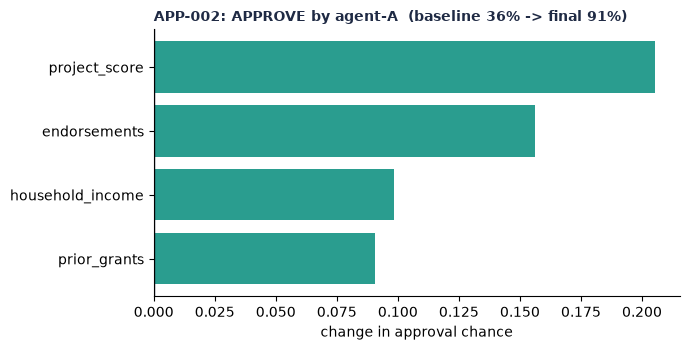

In [19]:
# TODO: make a changed application, e.g. sample_application("APP-002", prior_grants=3)
what_if = sample_application("APP-002")
d2 = agent_a.decide(what_if)
explain(d2)
draw_explanation(d2)

## 3. Deterministic or not?

**Your turn.** Ask the agent the same question 20 times and collect the answers.

In [20]:
from wonders import same_decision

answers = []
for _ in range(20):
    # TODO: append agent_a.decide(application) to answers
    pass

all_same = all(same_decision(answers[0], a) for a in answers)
print("20 runs, all identical?", all_same)

20 runs, all identical? True


For contrast, here is an agent that is **not** deterministic: it adds a little randomness, as many generative AI systems do by default.

In [21]:
import random

def moody_agent(application):
    d = agent_a.decide(application)
    p = d["explanation"]["final_p_approve"] + random.uniform(-0.5, 0.5)
    return "APPROVE" if p >= 0.5 else "REJECT"

print([moody_agent(application) for _ in range(12)])

['REJECT', 'APPROVE', 'APPROVE', 'APPROVE', 'APPROVE', 'APPROVE', 'APPROVE', 'REJECT', 'APPROVE', 'APPROVE', 'APPROVE', 'APPROVE']


If the same application can be approved in the morning and rejected in the afternoon, nobody can check a decision after the fact. Determinism is what makes **verification by replay** possible.

## 4. A fingerprint for the model

The agent's `model_hash` is the hash of its entire decision tree.

**Your turn.** Create two more agents: one with the same seed as agent A, one with a different seed. Predict which hashes will match before you run the cell.

In [22]:
# TODO: create an agent with seed=11 and another with seed=22
twin = DeterministicAgent(Wallet("agent-twin", role="agent"), seed=11)
agent_b = DeterministicAgent(Wallet("agent-B", role="agent"), seed=22)
print("agent A :", agent_a.model_hash[:16])
print("twin    :", twin.model_hash[:16], "(same seed)")
print("agent B :", agent_b.model_hash[:16], "(different seed)")

agent A : 7f5055ea018781d5
twin    : 7f5055ea018781d5 (same seed)
agent B : fcc766c54eb8ffa5 (different seed)


Same data, same settings, same seed: the same model, bit for bit. Change anything and the fingerprint changes. So the fingerprint tells us exactly **which model** made a decision.

## 5. Put the decision on the ledger

The decision record already carries its provenance. Look at it.

In [23]:
for key in ["application_id", "agent_id", "model_hash", "model_seed",
            "rules_version", "input_hash", "decision", "confidence", "decided_at"]:
    print(f"{key:<15} {decision[key]}")

application_id  APP-001
agent_id        agent-A
model_hash      7f5055ea018781d5a599a157ea9c488a5ae44f239558f6fa9dc227e05c9af7c5
model_seed      11
rules_version   grant-policy-v1
input_hash      d1155a698b6de966881291a2000c9085d1b46f309e30cec461c8a45efe5cbdc8
decision        APPROVE
confidence      0.908
decided_at      2026-11-15T15:45:41+00:00


**Your turn.** Write `record_decision`: the agent decides, then the agent's own wallet signs the decision onto the chain as a record of kind `"decision"`.

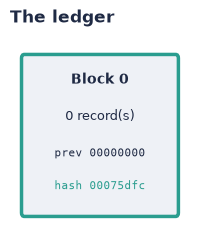

""


In [24]:
from wonders import Blockchain
from wonders.viz import draw_chain

ledger = Blockchain(difficulty=3)

def record_decision(chain, agent, application):
    decision = agent.decide(application)
    chain.record(agent.wallet, "decision", decision)
    return decision

record_decision(ledger, agent_a, sample_application("APP-001"))
record_decision(ledger, agent_b, sample_application("APP-001"))
record_decision(ledger, agent_a, sample_application("APP-002", prior_grants=3))
record_decision(ledger, agent_b, sample_application("APP-003", project_score=30, endorsements=1))

draw_chain(ledger)
pd.DataFrame([{"block": tx["block"], "signed by": tx["sender"],
               "application": tx["payload"]["application_id"],
               "decision": tx["payload"]["decision"],
               "model": tx["payload"]["model_hash"][:10],
               "time": tx["timestamp"]} for tx in ledger.transactions("decision")])

## 6. The auditor's questions

Six months later an auditor picks one decision from the ledger. Answer each question **using only the ledger and the registered agents**.

In [25]:
from wonders import verify_transaction, replay

record = ledger.transactions("decision")[2]
d = record["payload"]

print("What happened?      ", d["application_id"], "->", d["decision"])
print("Which agent acted?  ", record["sender"], "| signature valid:", verify_transaction(record))
print("Which model + rules?", d["model_hash"][:16], "|", d["rules_version"])
print("When?               ", record["timestamp"], "in block", record["block"])
print("Changed since?      ", "no" if ledger.is_valid() else "YES")
print("Why?")
for step in d["explanation"]["path"]:
    print("    ", step)

IndexError: list index out of range

**Your turn.** The strongest check: re-run the decision with the registered agent and compare. Use `replay(agent, recorded_decision)`.

In [ ]:
# TODO: call replay with agent_a and d
reproduces = None
print("Decision reproduces exactly?", reproduces)

## 7. Break it

Someone edits the ledger so that APP-003, which was rejected, reads APPROVE.

In [26]:
target = ledger.chain[4].transactions[0]
print("before:", target["payload"]["application_id"], target["payload"]["decision"])
target["payload"]["decision"] = "APPROVE"

print("ledger audit:")
for problem in ledger.audit():
    print("   ", problem)
print("replay check passes?", replay(agent_b, target["payload"]))
draw_chain(ledger, title="After someone edited a decision")

IndexError: list index out of range

Three independent alarms went off: the block hash, the agent's signature, and the replay.

## Discuss with your neighbour (3 minutes)

1. The explanation says *why the model decided*. Does it say whether the decision was *fair*? Who should judge that?
2. Agents A and B were trained on the same data but can disagree. What should happen then?
3. What would be lost if these agents were not deterministic?

**Next:** Activity 3 adds rules about who may do what.